# EquityVista — Exploratory Data Analysis
Daily OHLCV for the configured ticker (PTT.BK, 2016–2024), loaded from the cached CSV in `data/RAW/`. Goal: understand the series before modelling.

In [1]:
import sys, os, warnings
sys.path.insert(0, os.path.abspath(".."))   # repo root, so `import config`, `src.*` work
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import config as cfg
from src.fetch import fetch_data
from src.features import add_indicators
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": .3})
raw = fetch_data(cfg.TICKER, cfg.START, cfg.END)
print(cfg.TICKER, raw.index.min().date(), "->", raw.index.max().date())
raw.head()

PTT.BK 2016-01-04 -> 2024-12-30


,Open,High,Low,Close,Volume
Date,,,,,
2016-01-04,14.841180,14.960867,14.242745,14.242745,57964000
2016-01-05,14.302588,14.422275,13.464780,13.584467,88229000
2016-01-06,13.464777,13.704151,13.285247,13.644307,65320000
2016-01-07,12.866346,12.926190,12.327755,12.507285,182186000
2016-01-08,12.746661,12.986036,12.507287,12.866348,108961000


## Structure, missing values, summary statistics

In [2]:
raw.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 2186 entries, 2016-01-04 to 2024-12-30
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    2186 non-null   float64
 1   High    2186 non-null   float64
 2   Low     2186 non-null   float64
 3   Close   2186 non-null   float64
 4   Volume  2186 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 102.5 KB


In [3]:
print("Missing values per column:"); print(raw.isna().sum()); print("Duplicate dates:", raw.index.duplicated().sum())

Missing values per column:
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64
Duplicate dates: 0


In [4]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
Open,2186.0,2.790662e+01,4.459618e+00,11.908851,2.576736e+01,2.864356e+01,3.043378e+01,3.870236e+01
High,2186.0,2.816579e+01,4.477445e+00,12.088382,2.600592e+01,2.893437e+01,3.066828e+01,3.929677e+01
Low,2186.0,2.764327e+01,4.428263e+00,11.789165,2.555238e+01,2.842814e+01,3.014694e+01,3.804190e+01
Close,2186.0,2.789500e+01,4.446081e+00,11.849008,2.579133e+01,2.863512e+01,3.041295e+01,3.883444e+01
Volume,2186.0,5.771561e+07,4.179511e+07,0.000000,3.380668e+07,4.869290e+07,7.123118e+07,6.437820e+08


## Close price over time
The series is clearly **non-stationary** (trending, regime shifts such as the 2020 crash). This is why ARIMA uses differencing (`d=1`) and why we never shuffle when splitting.

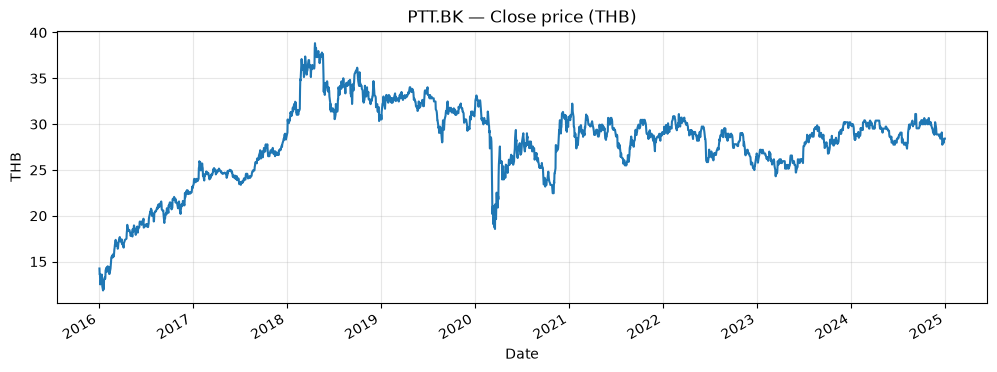

In [5]:
ax = raw["Close"].plot(title=f"{cfg.TICKER} — Close price (THB)")
ax.set_ylabel("THB"); plt.show()

## Volume

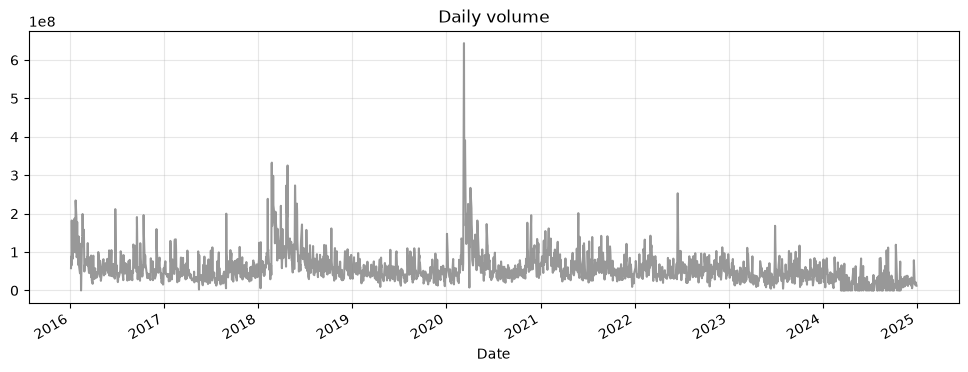

In [6]:
raw["Volume"].plot(color="tab:gray", title="Daily volume", alpha=.8); plt.show()

## Technical indicators
`add_indicators` adds Return, MA20/MA50, RSI(14), MACD and its signal line (the first ~50 rows are dropped because the rolling windows are not yet filled).

2186 -> 2137 rows after indicators


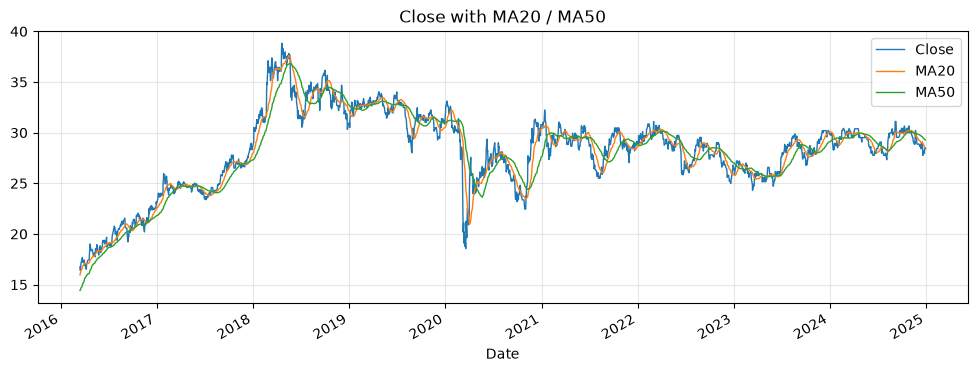

In [7]:
df = add_indicators(raw)
print(len(raw), "->", len(df), "rows after indicators")
df[["Close","MA20","MA50"]].plot(title="Close with MA20 / MA50", lw=1); plt.show()

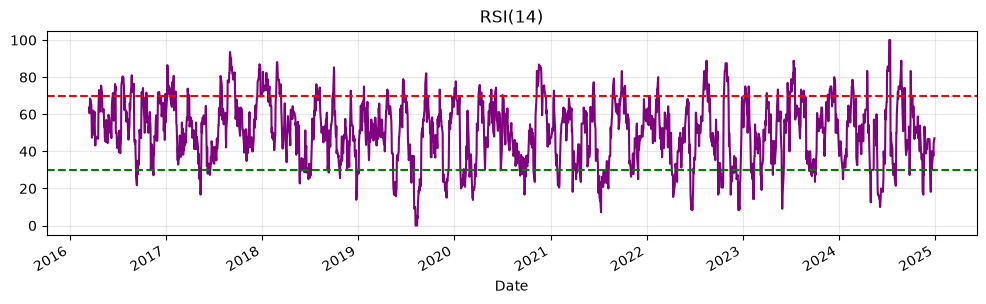

In [8]:
fig, ax = plt.subplots(figsize=(12, 3))
df["RSI"].plot(ax=ax, color="purple", title="RSI(14)")
ax.axhline(70, color="r", ls="--"); ax.axhline(30, color="g", ls="--"); plt.show()

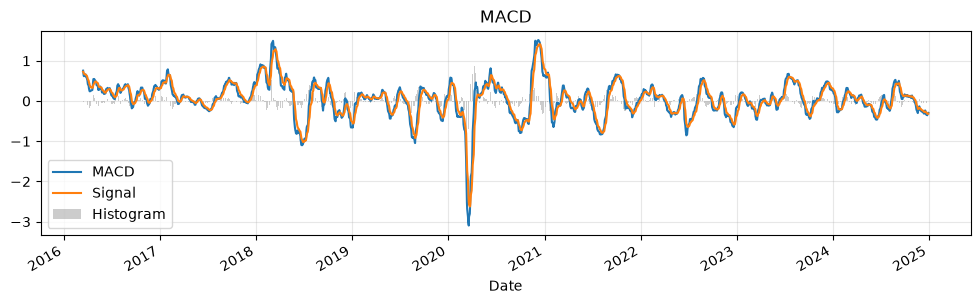

In [9]:
fig, ax = plt.subplots(figsize=(12, 3))
df["MACD"].plot(ax=ax, label="MACD"); df["Signal"].plot(ax=ax, label="Signal")
ax.bar(df.index, df["MACD"] - df["Signal"], width=1, color="grey", alpha=.4, label="Histogram")
ax.set_title("MACD"); ax.legend(); plt.show()

## Daily returns & the train/test split
Returns are roughly symmetric around 0 with fat tails. The split is **chronological**: the first 80% of days train, the last 20% test — no shuffling, so the models never see the future.

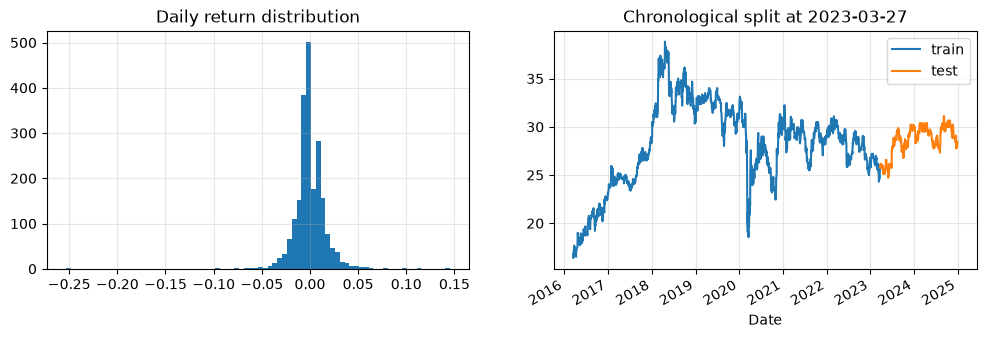

Share of up / down / flat days: {-1.0: 0.393, 1.0: 0.391, 0.0: 0.216}


In [10]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
df["Return"].hist(bins=80, ax=axs[0]); axs[0].set_title("Daily return distribution")
cut = int(len(df) * cfg.TEST_SPLIT)
df["Close"].iloc[:cut].plot(ax=axs[1], label="train"); df["Close"].iloc[cut:].plot(ax=axs[1], label="test")
axs[1].set_title(f"Chronological split at {df.index[cut].date()}"); axs[1].legend(); plt.show()
print("Share of up / down / flat days:", np.sign(df["Close"].diff().dropna()).value_counts(normalize=True).round(3).to_dict())